# Osa 2: Puheentunnistus Whisper-mallilla

## Kirjastot

In [1]:
import re
import time
import torch
import librosa
import librosa.display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from transformers import WhisperProcessor, WhisperForConditionalGeneration

# pip install transformers librosa ipywidgets sentencepiece sacremoses

## Ääninäytteet

In [2]:
# viite = oikea litterointi (sanasta sanaan se, mitä äänitteessä sanotaan)
# kieli = "fi" tai "en"
NAYTTEET = [
    {"nimi": "selkea_fi", "tiedosto": "voices/selkea_fi.wav", "kieli": "fi",
     "kuvaus": "Selkeä yleiskielinen puhe, hiljainen huone, puhelimen mikrofoni, puhuja 1",
     "viite": "Suomen luonto on kauneimmillaan kesällä, kun yöt ovat valoisia ja järvet tyyniä. Moni suomalainen viettää loman mökillä uiden, saunoen ja kalastaen. Syksyllä metsät täyttyvät sienestäjistä ja marjastajista, ja ensimmäiset pakkaset tuovat mukanaan kirkkaat tähtitaivaat."},
    {"nimi": "haly_fi", "tiedosto": "voices/haly_fi.wav", "kieli": "fi",
     "kuvaus": "Sääennuste luettuna taustahälyn kanssa, puhuja 1",
     "viite": "Huomenna sää on enimmäkseen pilvinen, ja iltapäivällä sataa paikoin vettä. Lämpötila nousee noin kahdeksaantoista asteeseen. Viikonloppuna aurinko näyttäytyy, mutta yöllä lämpötila voi laskea lähelle nollaa. Muistakaa pukeutua lämpimästi, jos lähdette ulos."},
    {"nimi": "puhuja2_fi", "tiedosto": "voices/puhuja2_fi.wav", "kieli": "fi",
     "kuvaus": "Selkeä yleiskielinen puhe, sama teksti kuin selkea_fi, puhuja 2",
     "viite": "Suomen luonto on kauneimmillaan kesällä, kun yöt ovat valoisia ja järvet tyyniä. Moni suomalainen viettää loman mökillä uiden, saunoen ja kalastaen. Syksyllä metsät täyttyvät sienestäjistä ja marjastajista, ja ensimmäiset pakkaset tuovat mukanaan kirkkaat tähtitaivaat."},
    {"nimi": "murre_fi", "tiedosto": "voices/murre_fi.wav", "kieli": "fi",
     "kuvaus": "Puhekielinen suomi, hiljainen huone, puhuja 1",
     "viite": "Mä oon tänää menny kauppaan ja ostin maitoo, leipää ja vähän juustoo. Sit mä kävelin kotiin ja kattelin telkkarii koko illan. Huomenna ei oo koulua, joten voin nukkuu pitkään."},
    {"nimi": "selkea_en", "tiedosto": "voices/selkea_en.wav", "kieli": "en",
     "kuvaus": "Englanninkielinen puhe, hiljainen huone, puhuja 1",
     "viite": "Finland is known for its thousands of lakes, its forests and its long, dark winters. In the summer the sun barely sets in the north, and people gather around campfires to enjoy the light. Many visitors come to see the northern lights and to try a traditional sauna."},
]

# Whisper-mallit (Hugging Face), vaihtoehtoja: tiny, base, small, medium, large-v3
MALLIT = ["tiny", "base", "small"]

In [3]:
# Load audio files (16 kHz, mono)
aanet = {}
for n in NAYTTEET:
    y, sr = librosa.load(n["tiedosto"], sr=16000)
    aanet[n["nimi"]] = y

    print(f"{n['nimi']}  ({n['tiedosto']})")
    display(Audio(y, rate=sr))
    print(f"Duration: {librosa.get_duration(y=y, sr=sr):.2f} seconds")
    print(f"Sample rate: {sr} Hz\n")

selkea_fi  (voices/selkea_fi.wav)


Duration: 27.14 seconds
Sample rate: 16000 Hz

haly_fi  (voices/haly_fi.wav)


Duration: 26.94 seconds
Sample rate: 16000 Hz

puhuja2_fi  (voices/puhuja2_fi.wav)


Duration: 22.41 seconds
Sample rate: 16000 Hz

murre_fi  (voices/murre_fi.wav)


Duration: 19.53 seconds
Sample rate: 16000 Hz

selkea_en  (voices/selkea_en.wav)


Duration: 27.38 seconds
Sample rate: 16000 Hz



## Mel-spektrogrammi

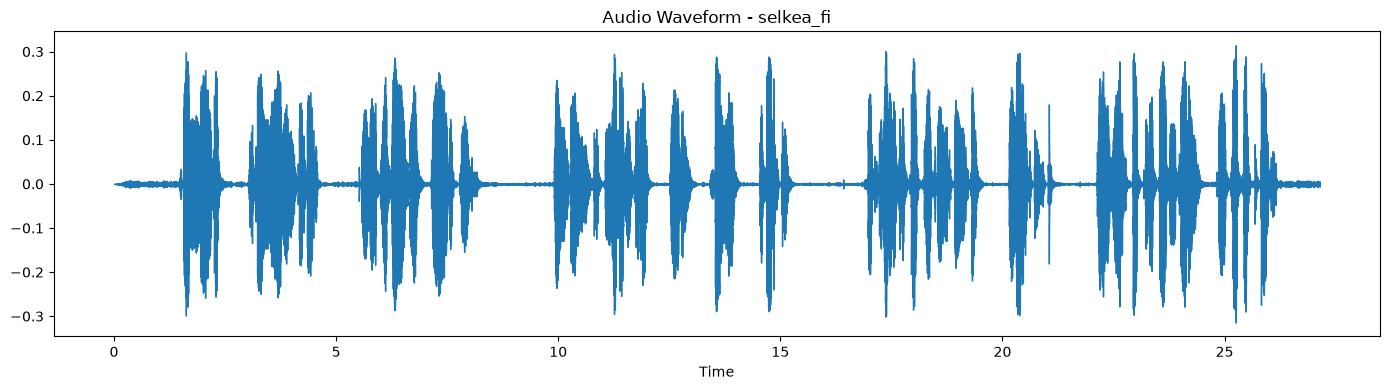

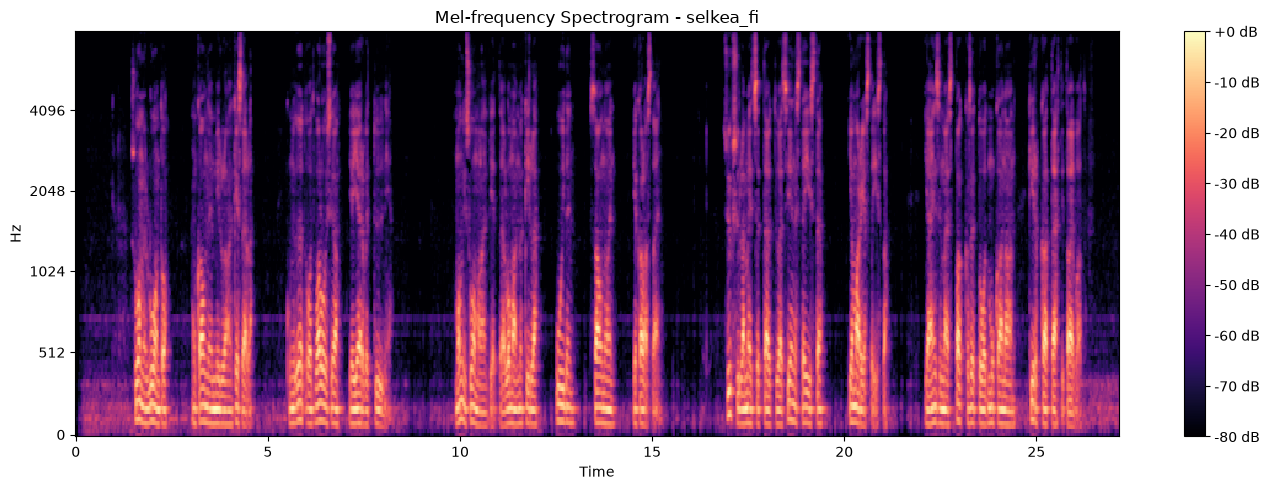

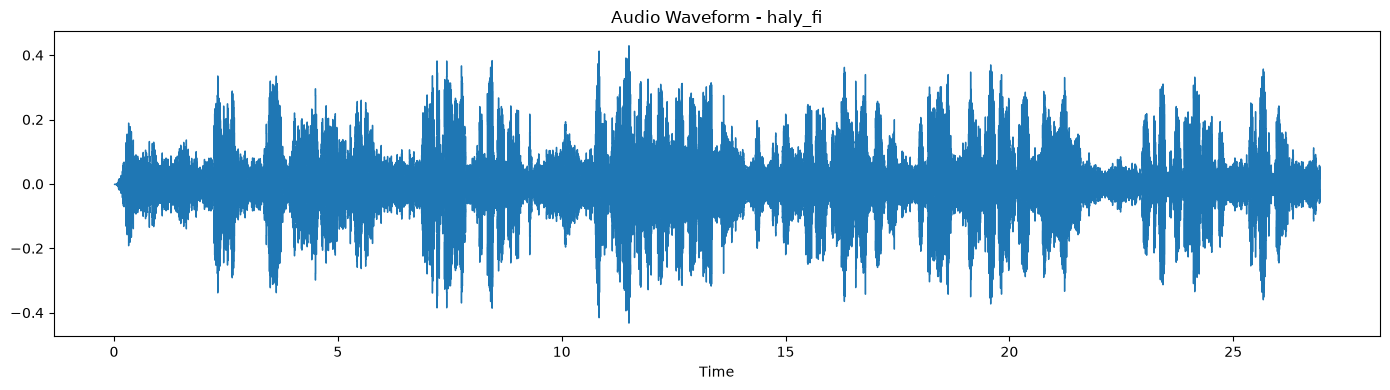

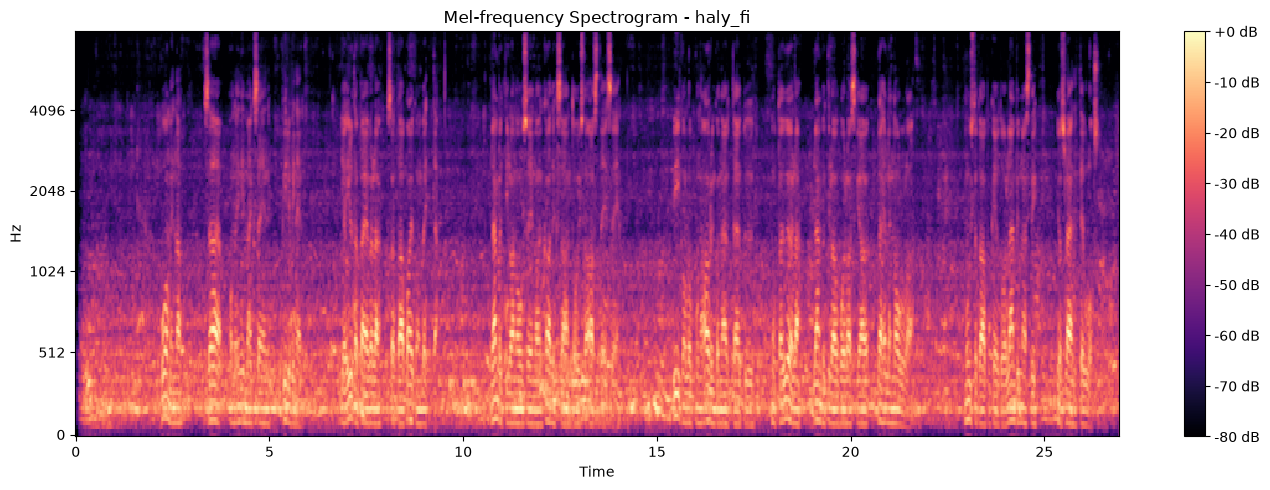

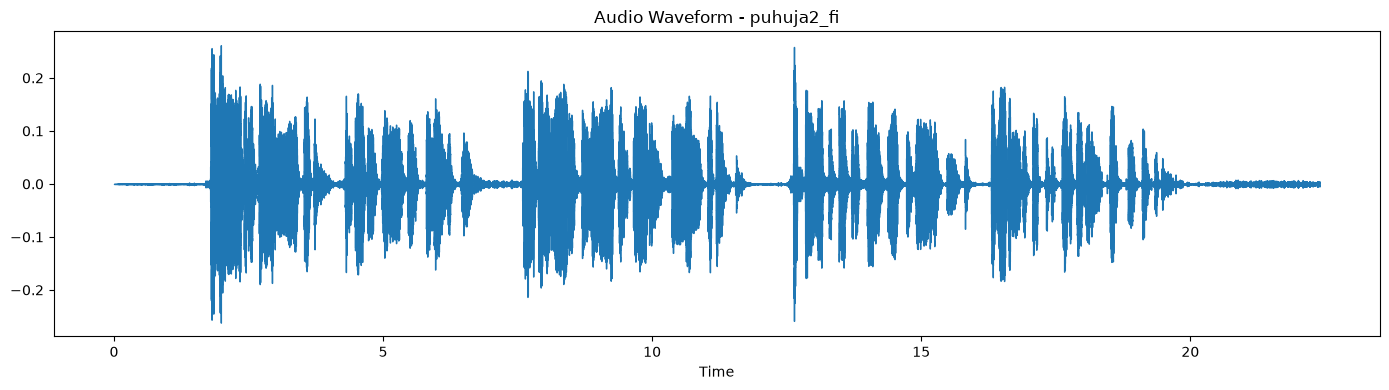

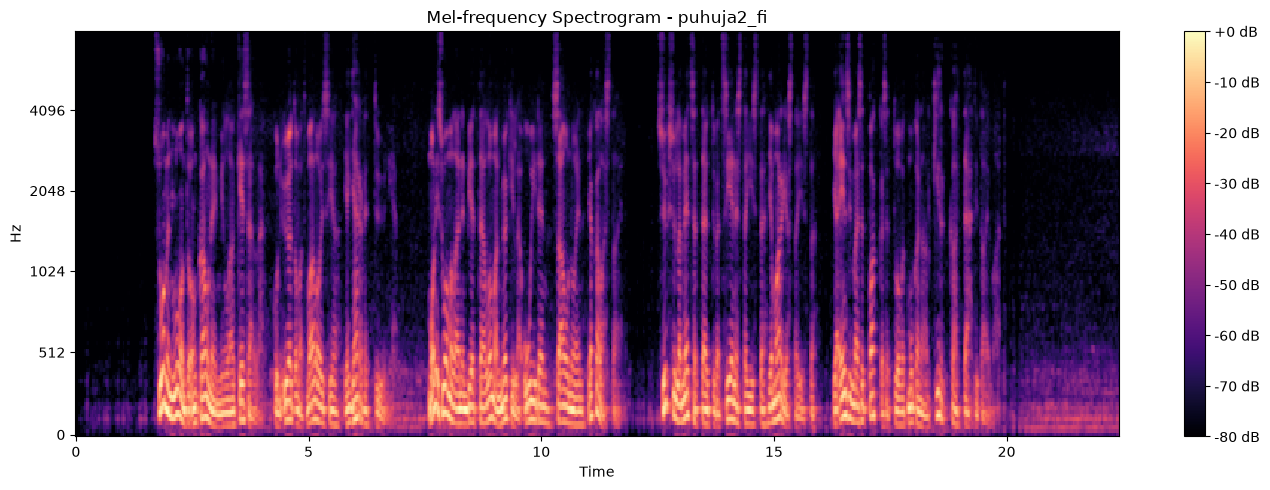

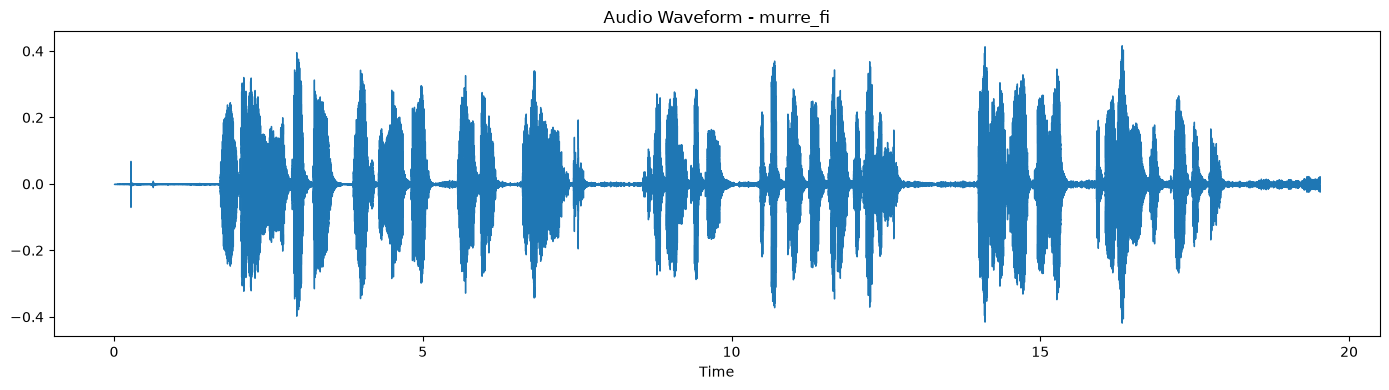

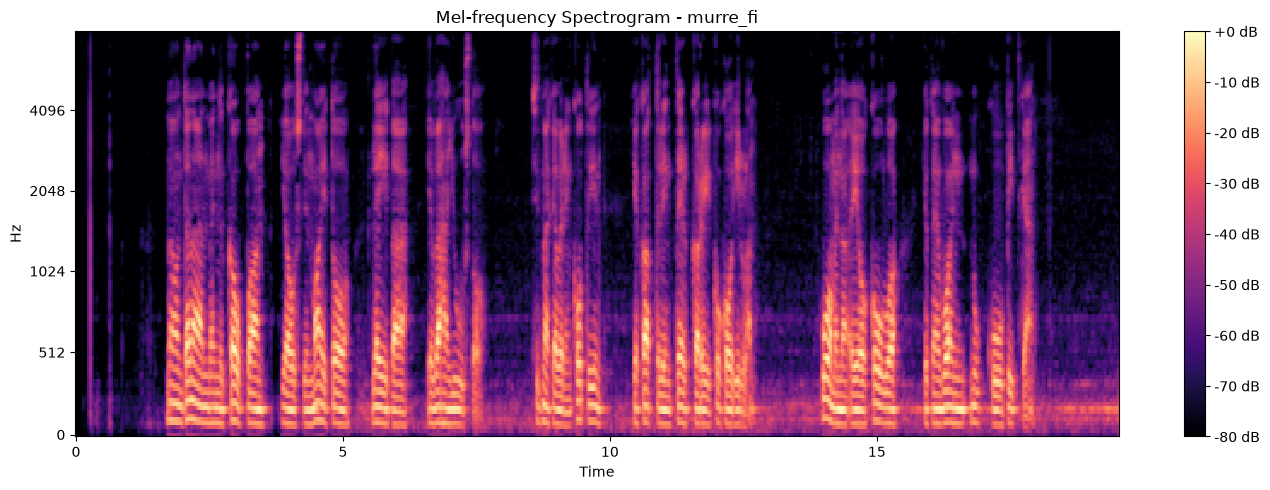

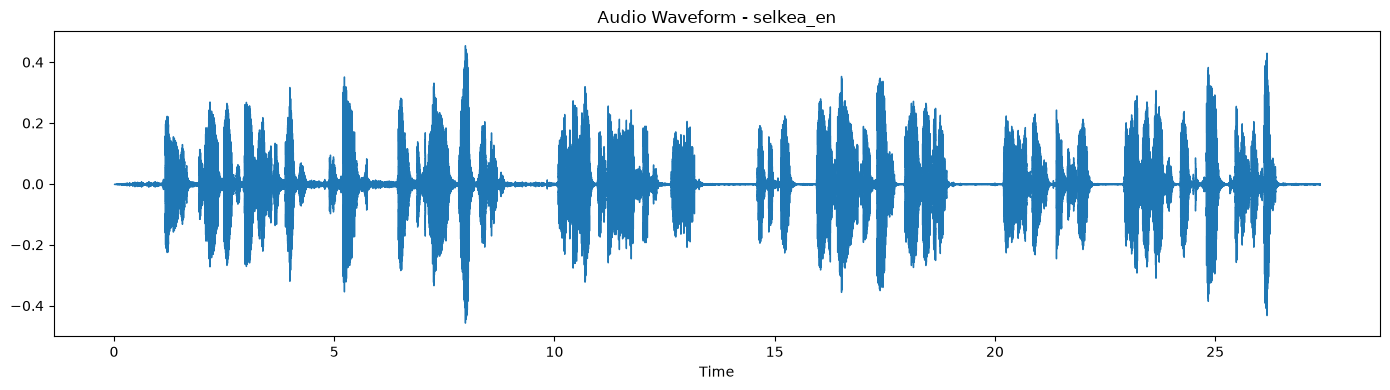

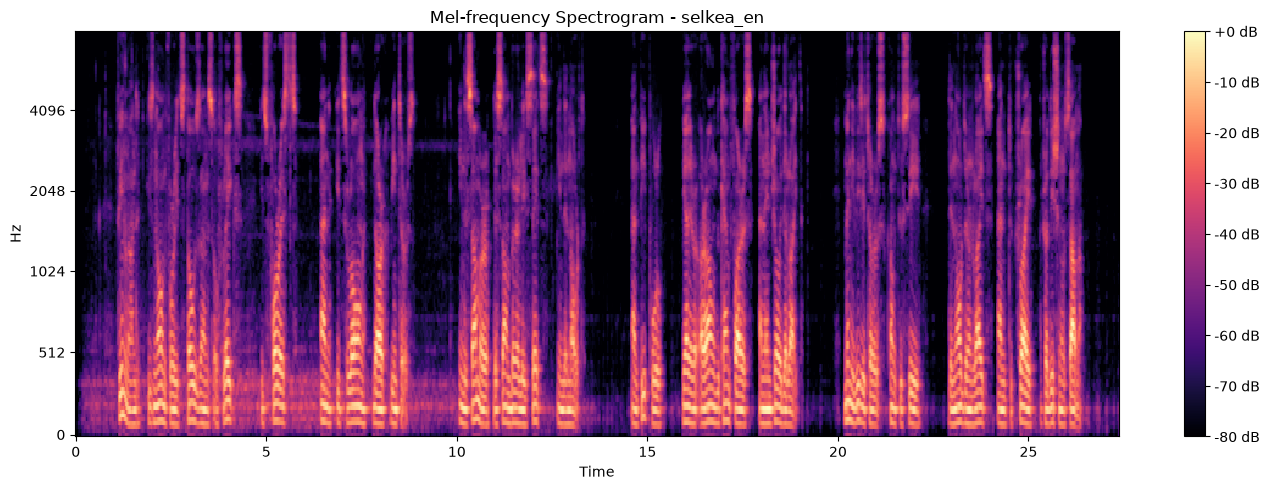

In [4]:
def piirra_aani(y, sr=16000, otsikko=""):
    # Plot waveform
    plt.figure(figsize=(14, 4))
    librosa.display.waveshow(y, sr=sr)
    plt.title(f'Audio Waveform - {otsikko}')
    plt.tight_layout()
    plt.show()

    # Create mel spectrogram
    plt.figure(figsize=(14, 5))
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
    S_dB = librosa.power_to_db(S, ref=np.max)
    librosa.display.specshow(S_dB, y_axis='mel', x_axis='time', sr=sr)
    plt.colorbar(format='%+2.0f dB')
    plt.title(f'Mel-frequency Spectrogram - {otsikko}')
    plt.tight_layout()
    plt.show()

for nimi, y in aanet.items():
    piirra_aani(y, otsikko=nimi)

## Mallien lataus

In [5]:
# Valitse laite: NVIDIA-GPU, Apple-GPU tai CPU
device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available()
          else "cpu")
print(f"Using device: {device}")

mallit = {}
for nimi in MALLIT:
    model_name = f"openai/whisper-{nimi}"
    t0 = time.perf_counter()
    processor = WhisperProcessor.from_pretrained(model_name)
    model = WhisperForConditionalGeneration.from_pretrained(model_name).to(device)
    mallit[nimi] = (processor, model)
    parametrit = sum(p.numel() for p in model.parameters())
    print(f"{model_name}: {parametrit/1e6:.0f} M parameters, load time {time.perf_counter() - t0:.1f} s")

Using device: cpu


preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/836k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

... (33 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.87k [00:00<?, ?B/s]

openai/whisper-small: 242 M parameters, load time 37.6 s


## Tunnistus

In [6]:
def tunnista(y, malli_nimi, kieli="fi", sr=16000):
    """Transcribe an audio array (< 30 s) with the chosen Whisper model. Returns (text, seconds)."""
    processor, model = mallit[malli_nimi]
    t0 = time.perf_counter()
    inputs = processor(y, sampling_rate=sr, return_tensors="pt").to(device, model.dtype)
    with torch.no_grad():
        generated_ids = model.generate(**inputs, language=kieli, task="transcribe")
    teksti = processor.batch_decode(generated_ids, skip_special_tokens=True,
                                    clean_up_tokenization_spaces=False)[0].strip()
    return teksti, time.perf_counter() - t0

rivit = []
for n in NAYTTEET:
    for m in MALLIT:
        teksti, aika = tunnista(aanet[n["nimi"]], m, n["kieli"])
        rivit.append({"nayte": n["nimi"], "malli": m, "aika_s": aika, "tunnistettu": teksti})
        print(f"[{m:>5}] {n['nimi']}: {teksti}")

tulokset = pd.DataFrame(rivit)

[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


[ tiny] selkea_fi: Suomen luonto on kaunnen millä on kesällä, kun nyt ovat valuus ja järvettyyn. Moni Suomalempietää lomannokilla, uiden, saunnoin ja kalastaen. Siksi yllämeet se täyttävät sienesteistä ja marjastaistä. Ja ensimmäistä pakka se tuot mukanaan kirkkat tähti taivaat.
[ base] selkea_fi: Suomen luonto on kaunnen millään kesällä, kun yöt ovat valoisia ja järvettyynia. Moni Suomalain piettään lomannutkinllä uiden, saunain ja kalastain. Syksyllä meidät sä täyttyvät sienesteistä ja marjastaista, ja ensimmäiset pakkaiset ovat mukanaan kirkaat tähti taivaat.
[small] selkea_fi: Suomen luonto on kauneen millaan kesällä, kun yöt ovat valoisia ja järvet tyyniä. Moni suomalain viettää loman mökillä uiden, saunoin ja kalastain. Syksyllä metsät täytyvät sienestäjistä ja mariastaista, ja ensimmäiset pakkaset ovat mukanaan kirkkat tähti taivaat.
[ tiny] haly_fi: Huomina saa on enimmäksiin pilvinen ja iltapäivällä saa tapaikon vettää. Lämpät tilana usein laikkaatiksaan toista asteseen. Viiko

## Vertailu: tarkkuus

In [7]:
def etaisyys(a, b):
    """Levenshtein distance between two sequences (words or characters)."""
    edellinen = list(range(len(b) + 1))
    for i, x in enumerate(a, 1):
        rivi = [i]
        for j, y in enumerate(b, 1):
            rivi.append(min(edellinen[j] + 1,              # deletion
                            rivi[j - 1] + 1,               # insertion
                            edellinen[j - 1] + (x != y)))  # substitution
        edellinen = rivi
    return edellinen[-1]

def wer(viite, tunnistettu):
    sanat = viite.split()
    return etaisyys(sanat, tunnistettu.split()) / len(sanat)

def cer(viite, tunnistettu):
    return etaisyys(viite, tunnistettu) / len(viite)

def normalisoi(s):
    s = s.lower()
    s = re.sub(r"[^\w\s]", "", s)
    return re.sub(r"\s+", " ", s).strip()

viitteet = {n["nimi"]: n["viite"] for n in NAYTTEET}

def virhe(mitta, rivi):
    viite = viitteet[rivi["nayte"]]
    if not viite:
        return np.nan
    return mitta(normalisoi(viite), normalisoi(rivi["tunnistettu"]))

tulokset["WER"] = tulokset.apply(lambda r: virhe(wer, r), axis=1)
tulokset["CER"] = tulokset.apply(lambda r: virhe(cer, r), axis=1)

display(tulokset.pivot(index="nayte", columns="malli", values="WER")[MALLIT])
display(tulokset.pivot(index="nayte", columns="malli", values="CER")[MALLIT])

malli,tiny,base,small
nayte,,,
haly_fi,0.774194,0.645161,0.258065
murre_fi,0.551724,0.413793,0.241379
puhuja2_fi,0.470588,0.352941,0.176471
selkea_en,0.041667,0.062500,0.041667
selkea_fi,0.735294,0.558824,0.323529


malli,tiny,base,small
nayte,,,
haly_fi,0.204000,0.160000,0.120000
murre_fi,0.188235,0.088235,0.052941
puhuja2_fi,0.087452,0.057034,0.026616
selkea_en,0.027027,0.050193,0.027027
selkea_fi,0.186312,0.117871,0.053232


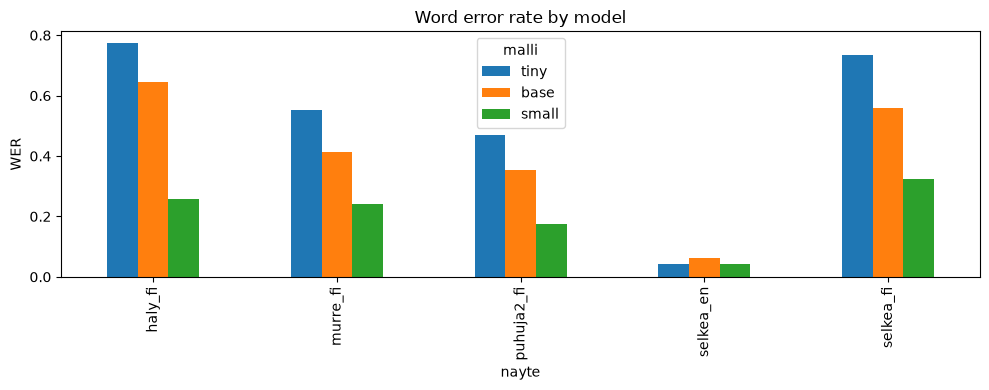

In [8]:
tulokset.pivot(index="nayte", columns="malli", values="WER")[MALLIT].plot.bar(figsize=(10, 4))
plt.ylabel("WER")
plt.title("Word error rate by model")
plt.tight_layout()
plt.show()

## Vertailu: nopeus

malli,tiny,base,small
nayte,,,
haly_fi,3.614810,9.454497,13.796264
murre_fi,2.419394,3.518593,9.202140
puhuja2_fi,3.220478,5.176757,11.861480
selkea_en,2.180724,3.008357,8.783375
selkea_fi,3.767904,6.784032,13.707834


,aika_s,RTF
malli,,
tiny,3.040662,0.124058
base,5.588447,0.224407
small,11.470219,0.467726


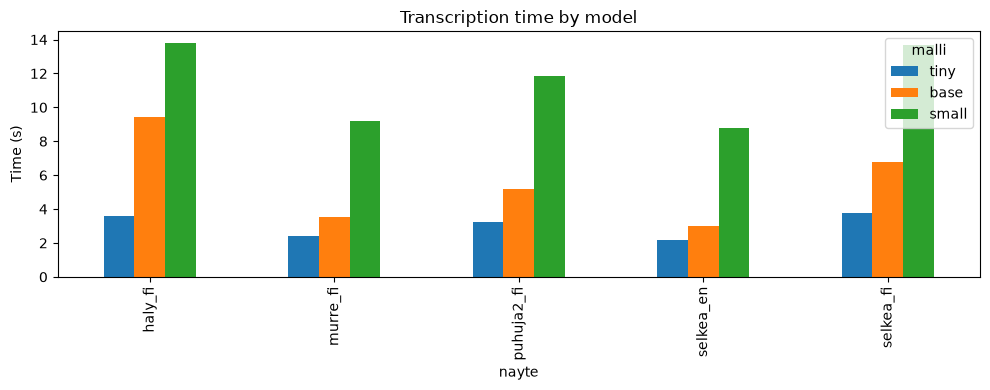

In [9]:
tulokset["kesto_s"] = tulokset["nayte"].map({k: len(y) / 16000 for k, y in aanet.items()})
tulokset["RTF"] = tulokset["aika_s"] / tulokset["kesto_s"]  # alle 1 = nopeampi kuin reaaliaika

display(tulokset.pivot(index="nayte", columns="malli", values="aika_s")[MALLIT])
display(tulokset.groupby("malli")[["aika_s", "RTF"]].mean().loc[MALLIT])

tulokset.pivot(index="nayte", columns="malli", values="aika_s")[MALLIT].plot.bar(figsize=(10, 4))
plt.ylabel("Time (s)")
plt.title("Transcription time by model")
plt.tight_layout()
plt.show()

## Tunnistetut tekstit rinnakkain

In [10]:
for n in NAYTTEET:
    print("=" * 80)
    print(n["nimi"], "-", n["kuvaus"])
    print("REFERENCE:", n["viite"])
    for m in MALLIT:
        r = tulokset[(tulokset.nayte == n["nimi"]) & (tulokset.malli == m)].iloc[0]
        print(f"{m:>6}: {r['tunnistettu']}")

selkea_fi - Selkeä yleiskielinen puhe, hiljainen huone, puhelimen mikrofoni, puhuja 1
REFERENCE: Suomen luonto on kauneimmillaan kesällä, kun yöt ovat valoisia ja järvet tyyniä. Moni suomalainen viettää loman mökillä uiden, saunoen ja kalastaen. Syksyllä metsät täyttyvät sienestäjistä ja marjastajista, ja ensimmäiset pakkaset tuovat mukanaan kirkkaat tähtitaivaat.
  tiny: Suomen luonto on kaunnen millä on kesällä, kun nyt ovat valuus ja järvettyyn. Moni Suomalempietää lomannokilla, uiden, saunnoin ja kalastaen. Siksi yllämeet se täyttävät sienesteistä ja marjastaistä. Ja ensimmäistä pakka se tuot mukanaan kirkkat tähti taivaat.
  base: Suomen luonto on kaunnen millään kesällä, kun yöt ovat valoisia ja järvettyynia. Moni Suomalain piettään lomannutkinllä uiden, saunain ja kalastain. Syksyllä meidät sä täyttyvät sienesteistä ja marjastaista, ja ensimmäiset pakkaiset ovat mukanaan kirkaat tähti taivaat.
 small: Suomen luonto on kauneen millaan kesällä, kun yöt ovat valoisia ja järvet tyyn

## Kohinakoe

In [11]:
def lisaa_kohinaa(y, snr_db):
    teho_signaali = np.mean(y ** 2)
    teho_kohina = teho_signaali / (10 ** (snr_db / 10))
    return (y + np.random.normal(0, np.sqrt(teho_kohina), y.shape)).astype(np.float32)

KOHINA_NAYTE = NAYTTEET[0]
SNR_ARVOT = [20, 10, 5, 0, -5]

np.random.seed(0)
kohina_rivit = []
for snr in SNR_ARVOT:
    meluisa = lisaa_kohinaa(aanet[KOHINA_NAYTE["nimi"]], snr)
    for m in MALLIT:
        teksti, aika = tunnista(meluisa, m, KOHINA_NAYTE["kieli"])
        wer_arvo = wer(normalisoi(KOHINA_NAYTE["viite"]), normalisoi(teksti)) if KOHINA_NAYTE["viite"] else np.nan
        kohina_rivit.append({"SNR_dB": snr, "malli": m, "WER": wer_arvo, "aika_s": aika, "tunnistettu": teksti})

kohina_tulokset = pd.DataFrame(kohina_rivit)
kohina_tulokset

,SNR_dB,malli,WER,aika_s,tunnistettu
0,20,tiny,0.852941,3.681778,"Suomen guonto on kaunnen millään kesällä, kun ..."
1,20,base,0.617647,5.765975,"Suomen vuonto on kaunnen millään kesällä, kun ..."
2,20,small,0.352941,10.981568,"Suomen luonto on kauneen millaan kesällä, kun ..."
3,10,tiny,0.970588,2.979813,Suomen guonto ja kaunneen miljoan kesällä. Min...
4,10,base,0.882353,4.439223,"Suomen vuonto, joka on niin midaan kesällä, ku..."
5,10,small,0.529412,11.436624,"Suomen luonto on kauneen miljoon kesällä, kun ..."
6,5,tiny,1.058824,2.826441,"Suomen vuonto, ja kaunneen mielenkiä sellainen..."
7,5,base,1.058824,4.975435,"Suomen luonto, joka on minun jo ensimmäisä. Mi..."
8,5,small,0.676471,12.219229,"Suomen luonto on kalmien ilojen kesällä, kun i..."
9,0,tiny,6.470588,10.927397,"Suomen juon, että niitä on koko. Niitä on jois..."


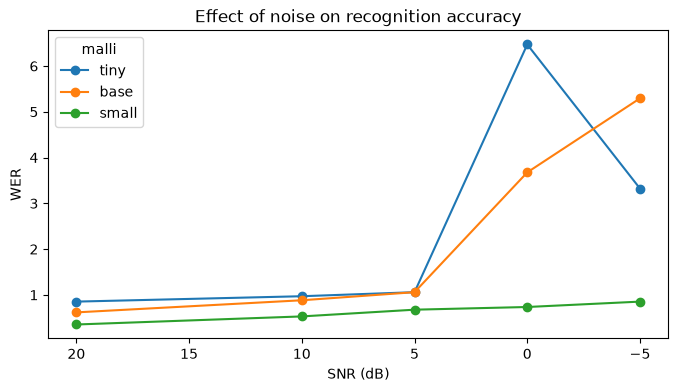

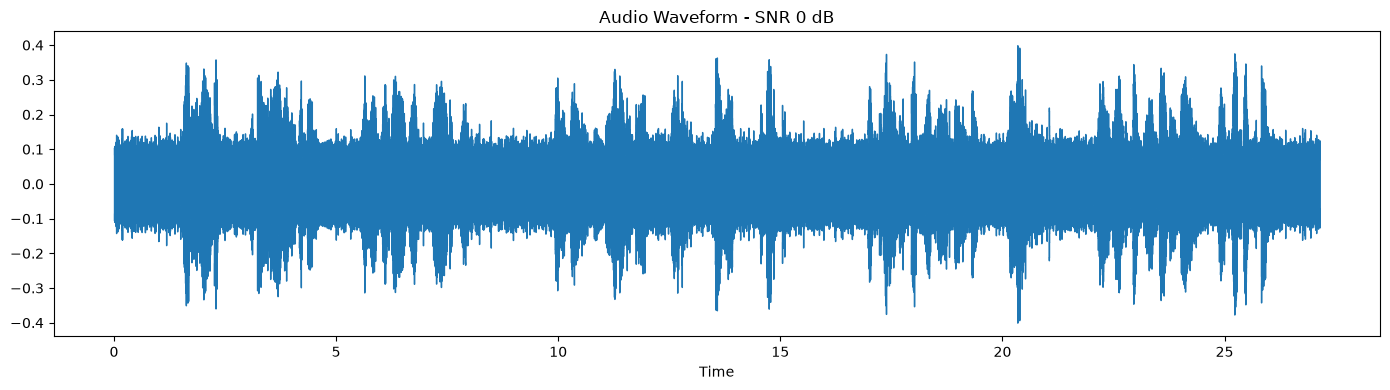

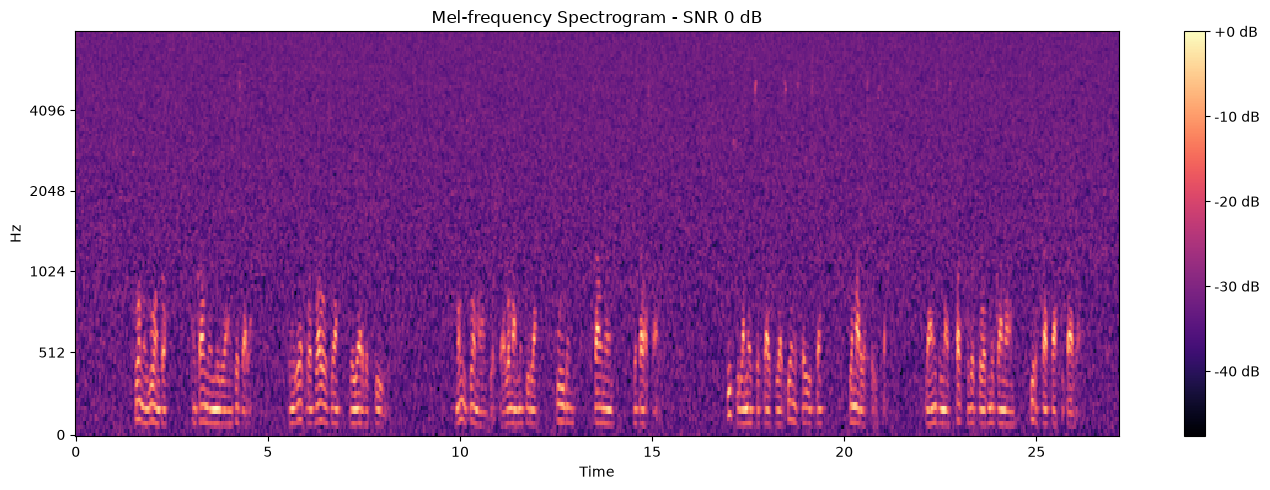

In [12]:
kohina_tulokset.pivot(index="SNR_dB", columns="malli", values="WER")[MALLIT].sort_index(ascending=False).plot(marker="o", figsize=(8, 4))
plt.xlabel("SNR (dB)")
plt.ylabel("WER")
plt.title("Effect of noise on recognition accuracy")
plt.gca().invert_xaxis()
plt.show()

piirra_aani(lisaa_kohinaa(aanet[KOHINA_NAYTE["nimi"]], 0), otsikko="SNR 0 dB")

## Kielen tunnistus ja englanninkielinen puhe

In [20]:
def tunnista_kieli(y, malli_nimi, sr=16000):
    # Kieltä ei anneta mallille, vaan Whisper arvaa sen äänestä
    processor, model = mallit[malli_nimi]
    inputs = processor(y, sampling_rate=sr, return_tensors="pt").to(device, model.dtype)
    with torch.no_grad():
        kieli_id = model.detect_language(input_features=inputs.input_features)
    return processor.tokenizer.decode(kieli_id[0]).strip("<|>")  # esim. "<|fi|>" -> "fi"

rivit = []
for n in NAYTTEET:
    for m in MALLIT:
        rivit.append({"nayte": n["nimi"], "oikea_kieli": n["kieli"], "malli": m,
                      "tunnistettu_kieli": tunnista_kieli(aanet[n["nimi"]], m)})
pd.DataFrame(rivit).pivot(index=["nayte", "oikea_kieli"], columns="malli", values="tunnistettu_kieli")[MALLIT]

,malli,tiny,base,small
nayte,oikea_kieli,,,
haly_fi,fi,fi,fi,fi
murre_fi,fi,fi,fi,fi
puhuja2_fi,fi,fi,fi,fi
selkea_en,en,en,la,en
selkea_fi,fi,fi,fi,fi


In [14]:
display(tulokset[tulokset.nayte.str.endswith("_en")][["nayte", "malli", "aika_s", "WER", "CER", "tunnistettu"]])
display(tulokset[tulokset.nayte.str.endswith("_fi")].groupby("malli")[["WER", "CER"]].mean().loc[MALLIT])

,nayte,malli,aika_s,WER,CER,tunnistettu
12,selkea_en,tiny,2.180724,0.041667,0.027027,"Finland is known for its thousands of lakes, i..."
13,selkea_en,base,3.008357,0.062500,0.050193,"Finland is known for its dozens of lakes, its ..."
14,selkea_en,small,8.783375,0.041667,0.027027,"Finland is known for its thousands of lakes, i..."


,WER,CER
malli,,
tiny,0.632950,0.166500
base,0.492680,0.105785
small,0.249861,0.063197


## Aikaleimat

In [15]:
processor, model = mallit[MALLIT[-1]]
y = aanet[NAYTTEET[0]["nimi"]]
inputs = processor(y, sampling_rate=16000, return_tensors="pt").to(device, model.dtype)
with torch.no_grad():
    ids = model.generate(**inputs, language="fi", task="transcribe", return_timestamps=True)

for o in processor.tokenizer.decode(ids[0], output_offsets=True)["offsets"]:
    print(f"[{o['timestamp'][0]:6.2f} - {o['timestamp'][1]:6.2f}]  {o['text'].strip()}")

[  0.00 -  16.00]  Suomen luonto on kauneen millaan kesällä, kun yöt ovat valoisia ja järvet tyyniä. Moni suomalain viettää loman mökillä uiden, saunoin ja kalastain.
[ 16.00 -  27.00]  Syksyllä metsät täytyvät sienestäjistä ja mariastaista, ja ensimmäiset pakkaset ovat mukanaan kirkkat tähti taivaat.


## Yhteenveto

In [16]:
tulokset.groupby("malli")[["WER", "CER", "aika_s", "RTF"]].mean().loc[MALLIT]

,WER,CER,aika_s,RTF
malli,,,,
tiny,0.514693,0.138605,3.040662,0.124058
base,0.406644,0.094667,5.588447,0.224407
small,0.208222,0.055963,11.470219,0.467726
